# 01 Data preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load WDI data and country metadata

In [2]:
wdi = pd.read_csv('../data/raw/WDICSV.csv')
meta = pd.read_csv('../data/raw/WDICountry.csv')
print(wdi.shape)
print(meta.shape)

(398468, 70)
(265, 31)


In [3]:
codes = ['NY.GDP.PCAP.CD', 'NY.GDP.MKTP.KD.ZG', 'FP.CPI.TOTL.ZG', 'SL.UEM.TOTL.ZS', 'NE.TRD.GNFS.ZS', 'NE.GDI.TOTL.ZS',
         'SP.DYN.LE00.IN', 'SP.URB.TOTL.IN.ZS', 'IT.NET.USER.ZS', 'EG.ELC.ACCS.ZS', 'SE.SEC.ENRR']
names = ['GDP_PC', 'GDP_GROWTH', 'INFLATION', 'UNEMPLOYMENT', 'TRADE', 'CAPITAL_FORMATION',
         'LIFE_EXPECTANCY', 'URBAN_POP', 'INTERNET_USERS', 'ELECTRICITY_ACCESS', 'SECONDARY_ENROLLMENT']

## Remove aggregates

In [4]:
print('all entries:', len(meta))
print('aggregates:', meta['Region'].isnull().sum())
print(meta[meta['Region'].isnull()]['Table Name'].head(10))
meta = meta.dropna(subset=['Region'])
print('countries:', len(meta))

all entries: 265
aggregates: 48
1                       Africa Eastern and Southern
3                        Africa Western and Central
7                                        Arab World
36                   Central Europe and the Baltics
49                           Caribbean small states
61      East Asia & Pacific (excluding high income)
62                       Early-demographic dividend
63                              East Asia & Pacific
64    Europe & Central Asia (excluding high income)
65                            Europe & Central Asia
Name: Table Name, dtype: object
countries: 217


In [5]:
df = pd.DataFrame({'country': meta['Table Name'], 'code': meta['Country Code'], 'region': meta['Region'],
                   'income_group': meta['Income Group'], 'lending_type': meta['Lending category']})
df['lending_type'] = df['lending_type'].fillna('Not classified')
print(df['income_group'].value_counts())
print(df['region'].value_counts())

income_group
High income            86
Upper middle income    59
Lower middle income    47
Low income             25
Name: count, dtype: int64
region
Europe & Central Asia         58
Sub-Saharan Africa            48
Latin America & Caribbean     42
East Asia & Pacific           37
Middle East & North Africa    23
South Asia                     6
North America                  3
Name: count, dtype: int64


## One row per country for a given year

In [6]:
def year_table(year):
    table = wdi.pivot_table(index='Country Code', columns='Indicator Code', values=str(year))
    table = table[codes]
    table.columns = names
    return table

## Coverage by year

In [7]:
coverage = {}
complete = []
for year in range(2015, 2025):
    table = year_table(year)
    values = pd.DataFrame()
    for name in names:
        values[name] = df['code'].map(table[name])
    coverage[year] = values.isnull().mean() * 100
    complete.append((values.isnull().sum(axis=1) == 0).sum())
coverage = pd.DataFrame(coverage).T.round(1)
coverage['complete countries'] = complete
coverage

,GDP_PC,GDP_GROWTH,INFLATION,UNEMPLOYMENT,TRADE,CAPITAL_FORMATION,LIFE_EXPECTANCY,URBAN_POP,INTERNET_USERS,ELECTRICITY_ACCESS,SECONDARY_ENROLLMENT,complete countries
2015,2.3,2.8,12.9,13.8,14.7,18.4,0.0,0.0,7.4,0.9,28.6,127
2016,2.8,3.2,12.9,13.8,15.2,18.9,0.0,0.0,6.5,0.9,32.3,121
2017,2.8,3.2,14.7,13.8,14.7,18.9,0.0,0.0,7.8,0.9,35.5,119
2018,2.8,2.8,15.2,13.8,14.7,18.9,0.0,0.0,16.1,0.9,35.5,112
2019,2.8,3.2,15.2,13.8,15.7,19.8,0.0,0.0,12.9,0.9,35.0,115
2020,3.2,3.2,17.5,13.8,15.2,19.4,0.0,0.0,15.2,0.9,33.2,112
2021,3.2,3.2,17.5,13.8,15.7,19.4,0.0,0.0,17.1,0.9,31.8,116
2022,3.7,3.7,17.5,14.3,15.7,19.4,0.0,0.0,16.1,0.9,35.5,110
2023,6.0,6.0,18.4,15.2,18.9,19.8,0.0,0.0,16.6,0.9,32.3,107
2024,7.8,7.8,18.9,16.1,20.7,22.1,0.0,0.0,16.1,0.9,49.8,75


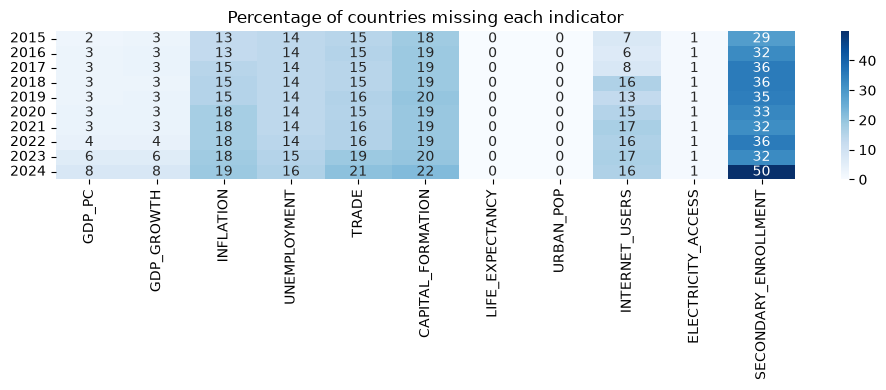

In [8]:
plt.figure(figsize=(10, 4))
sns.heatmap(coverage[names], annot=True, fmt='.0f', cmap='Blues')
plt.title('Percentage of countries missing each indicator')
plt.tight_layout()
plt.savefig('../figures/01_coverage_by_year.png', dpi=200)
plt.show()

## Year 2019

In [9]:
tables = {}
for year in [2017, 2018, 2019, 2020, 2021]:
    tables[year] = year_table(year)

for name in names:
    df[name] = df['code'].map(tables[2019][name])
print(df.shape)

(217, 16)


## Missing values before any change

In [10]:
missing = pd.DataFrame({'missing': df[names].isnull().sum(), 'percent': (df[names].isnull().mean() * 100).round(1)})
missing.sort_values('missing', ascending=False)

,missing,percent
SECONDARY_ENROLLMENT,76,35.0
CAPITAL_FORMATION,43,19.8
TRADE,34,15.7
INFLATION,33,15.2
UNEMPLOYMENT,30,13.8
INTERNET_USERS,28,12.9
GDP_GROWTH,7,3.2
GDP_PC,6,2.8
ELECTRICITY_ACCESS,2,0.9
LIFE_EXPECTANCY,0,0.0


In [11]:
df['n_missing'] = df[names].isnull().sum(axis=1)
print('countries with all 11 indicators:', (df['n_missing'] == 0).sum())
df['n_missing'].value_counts()

countries with all 11 indicators: 115


n_missing
0    115
1     42
2     18
3     16
4      9
5      8
6      6
7      3
Name: count, dtype: int64

In [12]:
df['incomplete'] = df['n_missing'] > 0
df.groupby('income_group')['incomplete'].mean().round(3) * 100

income_group
High income            39.5
Low income             76.0
Lower middle income    55.3
Upper middle income    39.0
Name: incomplete, dtype: float64

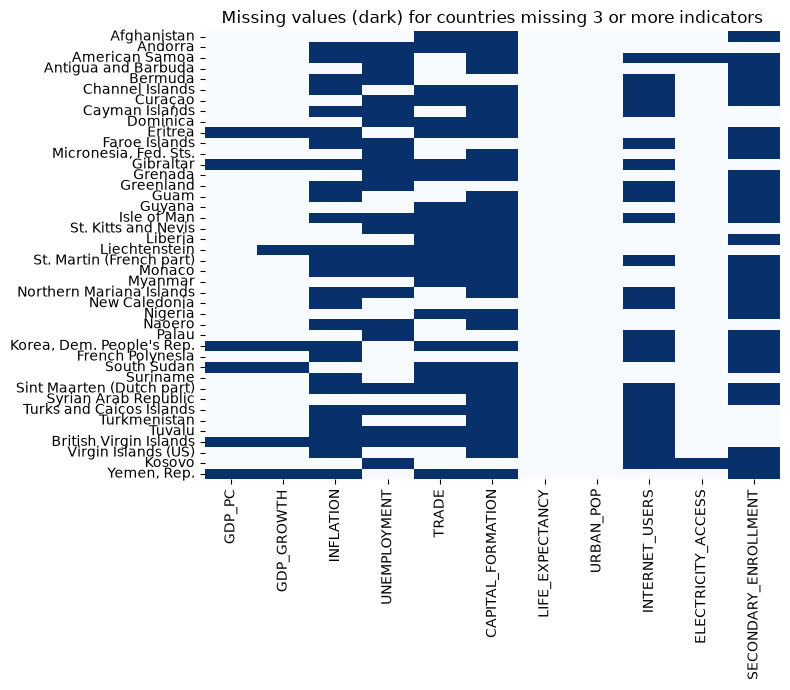

In [13]:
heavy = df[df['n_missing'] >= 3]
plt.figure(figsize=(8, 7))
sns.heatmap(heavy[names].isnull(), cbar=False, cmap='Blues', yticklabels=heavy['country'])
plt.title('Missing values (dark) for countries missing 3 or more indicators')
plt.tight_layout()
plt.savefig('../figures/01_missing_pattern.png', dpi=200)
plt.show()

## Fill from nearest year (slow-moving indicators only)

In [14]:
slow = ['GDP_PC', 'UNEMPLOYMENT', 'TRADE', 'CAPITAL_FORMATION', 'LIFE_EXPECTANCY', 'URBAN_POP',
        'INTERNET_USERS', 'ELECTRICITY_ACCESS', 'SECONDARY_ENROLLMENT']
before = df[names].isnull().sum()
for name in slow:
    for year in [2018, 2020, 2017, 2021]:
        df[name] = df[name].fillna(df['code'].map(tables[year][name]))
after = df[names].isnull().sum()
pd.DataFrame({'missing before': before, 'filled': before - after, 'missing after': after})

,missing before,filled,missing after
GDP_PC,6,1,5
GDP_GROWTH,7,0,7
INFLATION,33,0,33
UNEMPLOYMENT,30,0,30
TRADE,34,3,31
CAPITAL_FORMATION,43,3,40
LIFE_EXPECTANCY,0,0,0
URBAN_POP,0,0,0
INTERNET_USERS,28,15,13
ELECTRICITY_ACCESS,2,0,2


## Remove countries with 3 or more missing indicators

In [15]:
df['n_missing'] = df[names].isnull().sum(axis=1)
dropped = df[df['n_missing'] >= 3]
print('removed:', len(dropped))
dropped[['country', 'region', 'income_group', 'n_missing']].sort_values('n_missing', ascending=False)

removed: 31


,country,region,income_group,n_missing
84,Gibraltar,Europe & Central Asia,High income,7
192,"Korea, Dem. People's Rep.",East Asia & Pacific,Low income,7
108,Isle of Man,Europe & Central Asia,High income,6
224,Sint Maarten (Dutch part),Latin America & Caribbean,High income,6
254,British Virgin Islands,Latin America & Caribbean,High income,6
146,St. Martin (French part),Latin America & Caribbean,High income,6
11,American Samoa,East Asia & Pacific,High income,6
136,Liechtenstein,Europe & Central Asia,High income,5
148,Monaco,Europe & Central Asia,High income,5
215,South Sudan,Sub-Saharan Africa,Low income,5


In [16]:
df = df[df['n_missing'] <= 2]
print('countries kept:', len(df))
print('cells still missing:', df[names].isnull().sum().sum())
print(df[names].isnull().sum())
pd.crosstab(dropped['income_group'], dropped['region'])

countries kept: 186
cells still missing: 70
GDP_PC                   0
GDP_GROWTH               0
INFLATION                8
UNEMPLOYMENT             8
TRADE                   13
CAPITAL_FORMATION       14
LIFE_EXPECTANCY          0
URBAN_POP                0
INTERNET_USERS           3
ELECTRICITY_ACCESS       0
SECONDARY_ENROLLMENT    24
dtype: int64


region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,Middle East & North Africa,North America,Sub-Saharan Africa
income_group,,,,,,
High income,4,8,7,0,1,0
Low income,1,0,0,1,0,2
Upper middle income,2,2,3,0,0,0


## Save

In [17]:
df = df.drop(columns=['incomplete'])
df.to_csv('../data/processed/countries_2019.csv', index=False)
dropped.to_csv('../data/processed/dropped_countries_2019.csv', index=False)
df.head()

,country,code,region,income_group,lending_type,GDP_PC,GDP_GROWTH,INFLATION,UNEMPLOYMENT,TRADE,CAPITAL_FORMATION,LIFE_EXPECTANCY,URBAN_POP,INTERNET_USERS,ELECTRICITY_ACCESS,SECONDARY_ENROLLMENT,n_missing
0,Aruba,ABW,Latin America & Caribbean,High income,Not classified,30654.485124,1.229144,4.257462,NaN,137.923249,22.611388,76.019,62.288276,97.170000,100.0,139.320587,1
2,Afghanistan,AFG,Middle East & North Africa,Low income,IDA,496.602504,3.911603,2.302373,11.187,46.709895,11.500000,62.941,25.143726,17.600000,97.7,57.357849,0
4,Angola,AGO,Sub-Saharan Africa,Lower middle income,IBRD,2507.868072,-1.055234,17.080954,16.497,60.371307,24.536161,63.051,66.663782,32.129398,45.6,53.135154,0
5,Albania,ALB,Europe & Central Asia,Upper middle income,IBRD,6069.439031,2.062578,1.411091,11.466,75.382129,25.287526,79.467,56.763907,68.550391,100.0,99.015154,0
8,United Arab Emirates,ARE,Middle East & North Africa,High income,Not classified,45938.608457,1.271291,-1.931081,2.331,163.822149,23.185328,82.596,85.029826,99.149998,100.0,101.747344,0
